In [ ]:
# Define the local directory containing the chest X-ray dataset and verify that the expected dataset location is accessible.

import os

DATA_DIR = r"C:\Users\CSET343\chest_xray"

print("Dataset exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print("Contents:")
    print(os.listdir(DATA_DIR))


Dataset exists: True
Contents:
['.DS_Store', 'test', 'train', 'val']


In [2]:
# Install the external Python libraries required for image processing, feature extraction, machine learning, visualization, and deep learning.
%pip install -q scikit-image scikit-learn seaborn

# Import core Python libraries for file handling, numerical computation, tabular data manipulation, and visualization.
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from pathlib import Path

# Import image-processing utilities used to extract handcrafted texture and shape descriptors from chest X-ray images.
from skimage.feature import (
    hog,
    local_binary_pattern,
    graycomatrix,
    graycoprops
)

# Import the machine-learning utilities required for data splitting, feature standardization, and classical classification models.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics used to measure classification performance across the trained models.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Import TensorFlow and Keras components required to construct, train, and evaluate the convolutional neural network.
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Define fixed random seeds and common image-processing parameters to make experiments reproducible across executions.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


Note: you may need to restart the kernel to use updated packages.
TensorFlow: 2.21.0
GPU: []


In [3]:
# Traverse the dataset directory hierarchy to inspect its organization and report the number of image files found at relevant folder levels.

for root, dirs, files in os.walk(DATA_DIR):

    level = root.replace(DATA_DIR, "").count(os.sep)

    if level <= 2:
        print(
            "    " * level +
            os.path.basename(root) +
            "/"
        )

        if level == 2:
            print(
                "    " * (level + 1),
                len(files),
                "images"
            )


chest_xray/
    test/
        NORMAL/
             234 images
        PNEUMONIA/
             390 images
    train/
        NORMAL/
             1342 images
        PNEUMONIA/
             3876 images
    val/
        NORMAL/
             9 images
        PNEUMONIA/
             9 images


In [4]:
# Identify valid chest X-ray image files, associate each image with its corresponding diagnostic class, and construct a structured dataset.

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
}

image_paths = []
image_labels = []

for root, dirs, files in os.walk(DATA_DIR):

    folder_name = os.path.basename(root).upper()

    if folder_name not in CLASS_NAMES:
        continue

    for filename in files:

        extension = Path(filename).suffix.lower()

        if extension not in VALID_EXTENSIONS:
            continue

        path = os.path.join(root, filename)

        try:

            with Image.open(path) as img:
                img.verify()

            image_paths.append(path)
            image_labels.append(folder_name)

        except Exception:
            print("Invalid image:", path)


df = pd.DataFrame({
    "image_path": image_paths,
    "label": image_labels
})

df = df.drop_duplicates(
    subset="image_path"
).reset_index(drop=True)

print("Total images:", len(df))

display(df.head())


Total images: 5856


,image_path,label
0,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL
1,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL
2,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL
3,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL
4,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL


In [5]:
# Calculate the number and percentage of available images belonging to each diagnostic class.

class_counts = df["label"].value_counts()

print("Images per class:")
print(class_counts)

print("\nPercentage distribution:")
print(
    (class_counts / len(df) * 100).round(2)
)


Images per class:
label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Percentage distribution:
label
PNEUMONIA    72.97
NORMAL       27.03
Name: count, dtype: float64


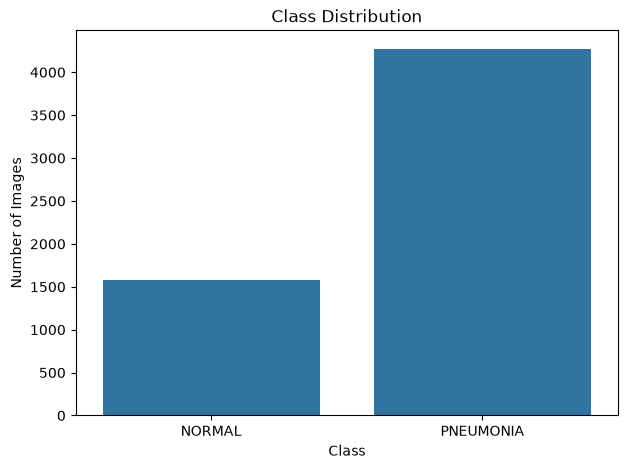

In [6]:
# Create a class-frequency visualization to examine whether the dataset is balanced across NORMAL and PNEUMONIA categories.

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label",
    order=CLASS_NAMES
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()


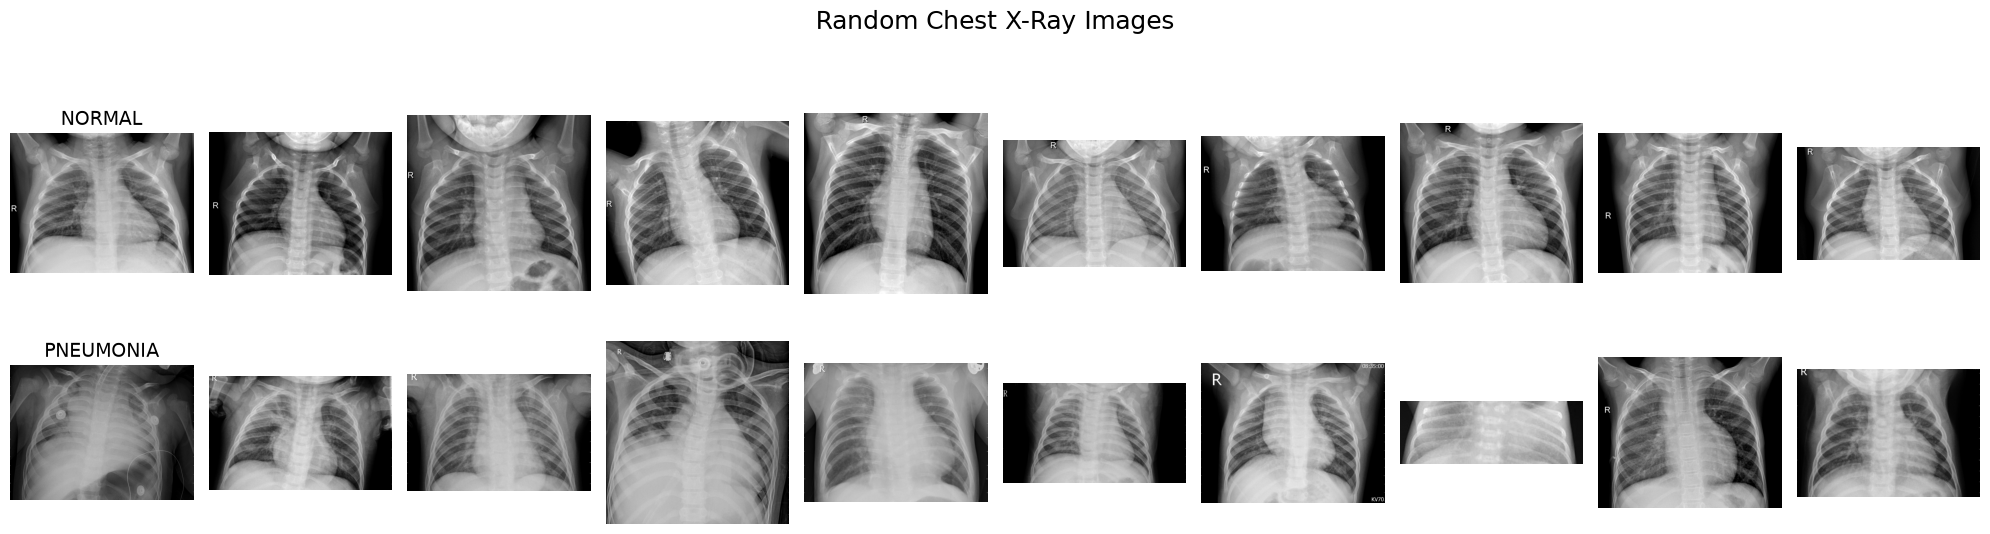

In [7]:
# Display representative randomly selected X-ray images from each class to visually inspect the dataset and verify class labeling.

fig, axes = plt.subplots(
    2,
    10,
    figsize=(20, 6)
)

for row, class_name in enumerate(CLASS_NAMES):

    class_data = df[
        df["label"] == class_name
    ]

    samples = class_data.sample(
        n=min(10, len(class_data)),
        random_state=SEED
    )

    for col, (_, sample) in enumerate(
        samples.iterrows()
    ):

        image = Image.open(
            sample["image_path"]
        ).convert("L")

        axes[row, col].imshow(
            image,
            cmap="gray"
        )

        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(
                class_name,
                fontsize=14
            )

    # Hide subplot axes that do not contain a sampled image so that the visualization remains clean and uncluttered.
    for col in range(len(samples), 10):
        axes[row, col].axis("off")


plt.suptitle(
    "Random Chest X-Ray Images",
    fontsize=18
)

plt.tight_layout()
plt.show()


In [9]:
# DATA PREPROCESSING: Prepare the image metadata and labels for subsequent model training and evaluation.

# Convert the categorical class labels into numerical target values required by the machine-learning and deep-learning models.

df["target"] = df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
})

display(df.head())
display(df.tail())


,image_path,label,target
0,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL,0
1,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL,0
2,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL,0
3,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL,0
4,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,NORMAL,0


,image_path,label,target
5851,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,PNEUMONIA,1
5852,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,PNEUMONIA,1
5853,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,PNEUMONIA,1
5854,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,PNEUMONIA,1
5855,C:\Users\arkad\OneDrive\Desktop\CSET343\LAB-3\...,PNEUMONIA,1


In [10]:
# Partition the dataset into training, validation, and independent testing subsets while preserving the class distribution through stratified sampling.

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["target"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["target"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTotal:")
print(
    len(train_df) +
    len(val_df) +
    len(test_df)
)


Training images: 4099
Validation images: 878
Testing images: 879

Total:
5856


In [11]:
# Define the image preprocessing pipeline by resizing X-ray images to a consistent spatial resolution and normalizing pixel intensities to the [0, 1] range.

IMG_SIZE = (128, 128)

def load_images(dataframe):

    images = []
    labels = []

    for _, row in dataframe.iterrows():

        image = Image.open(
            row["image_path"]
        ).convert("L")

        image = image.resize(
            IMG_SIZE
        )

        image = np.array(
            image,
            dtype=np.float32
        )

        image = image / 255.0

        images.append(image)
        labels.append(row["target"])

    return (
        np.array(images),
        np.array(labels)
    )


In [12]:
# Load and preprocess the training, validation, and test images, returning image arrays and their corresponding numerical labels.

X_train, y_train = load_images(train_df)

X_val, y_val = load_images(val_df)

X_test, y_test = load_images(test_df)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


X_train: (4099, 128, 128)
X_val: (878, 128, 128)
X_test: (879, 128, 128)


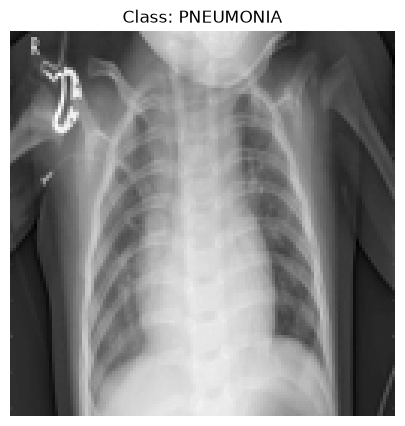

In [13]:
# Visualize a preprocessed training image to verify the resizing, grayscale conversion, and pixel normalization steps.

plt.figure(figsize=(5, 5))

plt.imshow(
    X_train[0],
    cmap="gray"
)

plt.title(
    f"Class: {CLASS_NAMES[y_train[0]]}"
)

plt.axis("off")

plt.show()


In [14]:
# Define Histogram of Oriented Gradients (HOG) extraction to capture local edge and shape information from the preprocessed X-ray images.

def extract_hog(image):

    features, hog_image = hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True,
        feature_vector=True
    )

    return features, hog_image


In [15]:
# Extract HOG descriptors from a representative training image and report the dimensionality of the resulting feature vector.

hog_features, hog_image = extract_hog(
    X_train[0]
)

print(
    "HOG feature vector size:",
    len(hog_features)
)


HOG feature vector size: 8100


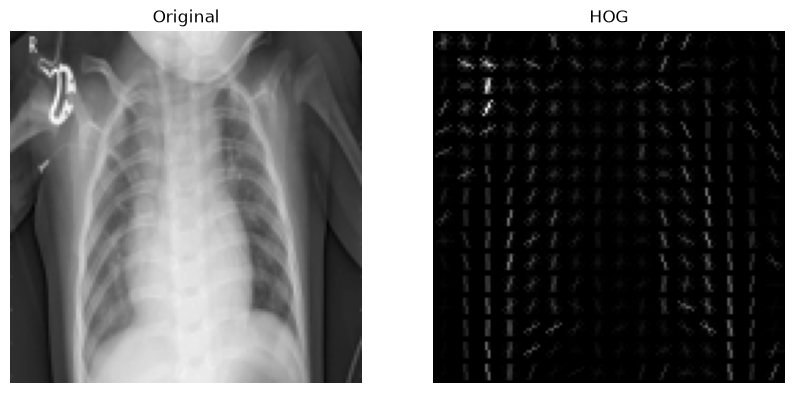

In [16]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)

axes[0].imshow(
    X_train[0],
    cmap="gray"
)

axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(
    hog_image,
    cmap="gray"
)

axes[1].set_title("HOG")
axes[1].axis("off")

plt.show()


In [17]:
# Define Local Binary Pattern (LBP) extraction to represent local texture patterns within the preprocessed X-ray images.

def extract_lbp(image):

    image_uint8 = (
        image * 255
    ).astype(np.uint8)

    radius = 1

    points = 8 * radius

    lbp = local_binary_pattern(
        image_uint8,
        points,
        radius,
        method="uniform"
    )

    histogram, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(
            0,
            points + 3
        ),
        range=(
            0,
            points + 2
        )
    )

    histogram = histogram.astype(
        np.float32
    )

    histogram /= (
        histogram.sum() + 1e-8
    )

    return histogram, lbp


In [18]:
# Extract LBP descriptors from a representative training image and report the dimensionality of the resulting texture feature vector.

lbp_features, lbp_image = extract_lbp(
    X_train[0]
)

print(
    "LBP feature vector size:",
    len(lbp_features)
)


LBP feature vector size: 10


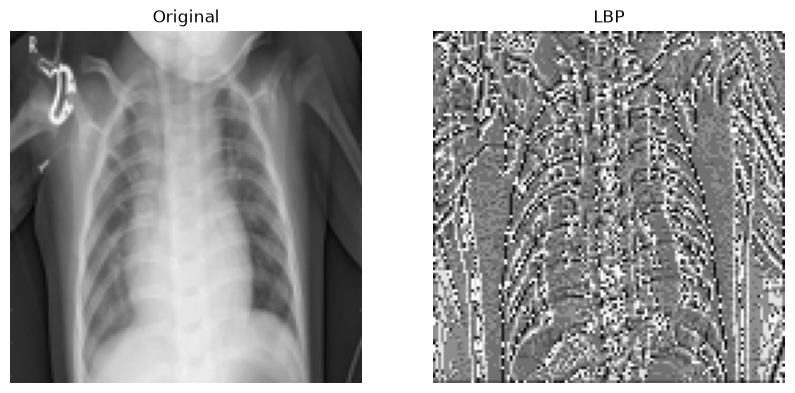

In [19]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)

axes[0].imshow(
    X_train[0],
    cmap="gray"
)

axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(
    lbp_image,
    cmap="gray"
)

axes[1].set_title("LBP")
axes[1].axis("off")

plt.show()


In [20]:
# Define GLCM-based texture feature extraction to quantify spatial relationships and intensity patterns within the X-ray images.

def extract_glcm(image):

    # Quantize normalized pixel intensities from the [0, 1] range into 32 discrete gray levels so that the GLCM can be computed efficiently.
    image_uint8 = (
        image * 31
    ).astype(np.uint8)

    glcm = graycomatrix(
        image_uint8,
        distances=[1, 2],
        angles=[
            0,
            np.pi / 4,
            np.pi / 2,
            3 * np.pi / 4
        ],
        levels=32,
        symmetric=True,
        normed=True
    )

    properties = [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation",
        "ASM"
    ]

    features = []

    for property_name in properties:

        values = graycoprops(
            glcm,
            property_name
        )

        features.extend(
            values.flatten()
        )

    return np.array(
        features,
        dtype=np.float32
    )


In [21]:
# Extract GLCM texture descriptors from a representative training image and inspect the resulting feature vector.

glcm_features = extract_glcm(
    X_train[0]
)

print(
    "GLCM feature vector size:",
    len(glcm_features)
)

print(glcm_features)


GLCM feature vector size: 48
[1.6403174  1.8927398  0.6937746  1.9490979  3.9786706  1.8927398
 1.6374007  1.9490979  0.7162278  0.77661353 0.37942913 0.7941596
 1.2606647  0.77661353 0.6631944  0.7941596  0.71122    0.6920813
 0.83318025 0.6885041  0.5658939  0.6920813  0.7358958  0.6885041
 0.14294797 0.13936383 0.17357871 0.13780877 0.11463594 0.13936383
 0.1498222  0.13780877 0.97444004 0.9703834  0.9891896  0.96950114
 0.93773013 0.9703834  0.9743819  0.96950114 0.02043412 0.01942228
 0.03012957 0.01899126 0.0131414  0.01942228 0.02244669 0.01899126]


In [22]:
# Combine HOG, LBP, and GLCM descriptors into a single handcrafted feature vector for each image.

from tqdm.auto import tqdm

def extract_combined_features(images):

    all_features = []

    for image in tqdm(images):

        hog_vector, _ = extract_hog(
            image
        )

        lbp_vector, _ = extract_lbp(
            image
        )

        glcm_vector = extract_glcm(
            image
        )

        combined = np.concatenate([
            hog_vector,
            lbp_vector,
            glcm_vector
        ])

        all_features.append(
            combined
        )

    return np.array(
        all_features,
        dtype=np.float32
    )


c:\Users\arkad\OneDrive\Desktop\CSET343\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [23]:
X_train_features = extract_combined_features(
    X_train
)

X_val_features = extract_combined_features(
    X_val
)

X_test_features = extract_combined_features(
    X_test
)

print(
    "Training feature shape:",
    X_train_features.shape
)

print(
    "Validation feature shape:",
    X_val_features.shape
)

print(
    "Testing feature shape:",
    X_test_features.shape
)


100%|██████████| 879/879 [00:34<00:00, 25.85it/s]

Training feature shape: (4099, 8158)
Validation feature shape: (878, 8158)
Testing feature shape: (879, 8158)


In [24]:
# Prepare the preprocessed grayscale images in the four-dimensional tensor format required by a convolutional neural network.

X_train_cnn = np.expand_dims(
    X_train,
    axis=-1
)

X_val_cnn = np.expand_dims(
    X_val,
    axis=-1
)

X_test_cnn = np.expand_dims(
    X_test,
    axis=-1
)

print(
    "Training:",
    X_train_cnn.shape
)

print(
    "Validation:",
    X_val_cnn.shape
)

print(
    "Testing:",
    X_test_cnn.shape
)


Training: (4099, 128, 128, 1)
Validation: (878, 128, 128, 1)
Testing: (879, 128, 128, 1)


In [25]:
# Construct and compile a convolutional neural network with progressive convolutional feature extraction, pooling, regularization, and binary classification layers.

def build_cnn(
    filters=32,
    dropout_rate=0.3,
    learning_rate=0.001
):

    model = models.Sequential([

        layers.Input(
            shape=(128, 128, 1)
        ),

        # Convolutional block 1: extract low-level visual patterns and reduce spatial dimensions through max pooling.
        layers.Conv2D(
            filters,
            (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D(
            (2, 2)
        ),

        # Convolutional block 2: learn increasingly complex spatial features using a larger number of convolutional filters.
        layers.Conv2D(
            filters * 2,
            (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D(
            (2, 2)
        ),

        # Convolutional block 3: capture higher-level image representations before classification.
        layers.Conv2D(
            filters * 4,
            (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D(
            (2, 2)
        ),

        # Classification head: aggregate learned spatial features, apply a dense representation with dropout regularization, and produce the binary prediction.
        layers.GlobalAveragePooling2D(),

        layers.Dense(
            64,
            activation="relu"
        ),

        layers.Dropout(
            dropout_rate
        ),

        # Output layer for binary classification, returning the probability that the image belongs to the positive class (PNEUMONIA).
        layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),

        loss="binary_crossentropy",

        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(
                name="auc"
            )
        ]
    )

    return model


In [ ]:
# Initialize the baseline CNN architecture and display its layer structure, parameter counts, and output dimensions.

cnn_model = build_cnn()

cnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Train the baseline CNN while monitoring validation loss and restoring the model weights from the best validation epoch.

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = cnn_model.fit(

    X_train_cnn,
    y_train,

    validation_data=(
        X_val_cnn,
        y_val
    ),

    epochs=20,

    batch_size=32,

    callbacks=[
        early_stopping
    ],

    verbose=1
)


Epoch 1/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 41s 296ms/step - accuracy: 0.7297 - auc: 0.5078 - loss: 0.5925 - val_accuracy: 0.7301 - val_auc: 0.6843 - val_loss: 0.5764
Epoch 2/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 33s 257ms/step - accuracy: 0.7282 - auc: 0.7281 - loss: 0.5091 - val_accuracy: 0.7301 - val_auc: 0.7836 - val_loss: 0.4920
Epoch 3/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 34s 262ms/step - accuracy: 0.7329 - auc: 0.7722 - loss: 0.4839 - val_accuracy: 0.7665 - val_auc: 0.8135 - val_loss: 0.4846
Epoch 4/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 35s 268ms/step - accuracy: 0.7790 - auc: 0.8381 - loss: 0.4400 - val_accuracy: 0.7654 - val_auc: 0.8649 - val_loss: 0.4575
Epoch 5/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 39s 306ms/step - accuracy: 0.8165 - auc: 0.8773 - loss: 0.3839 - val_accuracy: 0.8451 - val_auc: 0.9102 - val_loss: 0.3431
Epoch 6/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 37s 290ms/step - accuracy: 0.8448 - auc: 0.9084 - loss: 0.3367 - val_accuracy: 0.8667 - val_auc: 0.9280 - val_loss: 0.3049
Epoch 7/20
129/129 ━━━

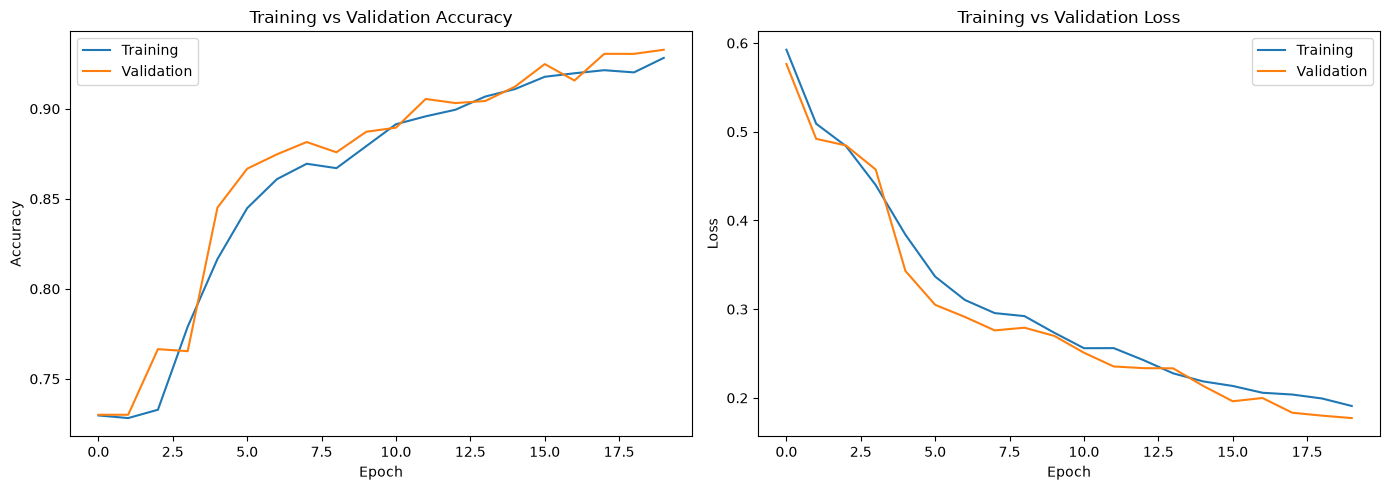

In [28]:
# Visualize the CNN learning process by comparing training and validation accuracy and loss across epochs.

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Plot training and validation accuracy to assess learning progress and identify potential overfitting or underfitting.
axes[0].plot(
    history.history["accuracy"],
    label="Training"
)

axes[0].plot(
    history.history["val_accuracy"],
    label="Validation"
)

axes[0].set_title(
    "Training vs Validation Accuracy"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[0].legend()


# Plot training and validation loss to assess optimization behavior and generalization during model training.
axes[1].plot(
    history.history["loss"],
    label="Training"
)

axes[1].plot(
    history.history["val_loss"],
    label="Validation"
)

axes[1].set_title(
    "Training vs Validation Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

axes[1].legend()

plt.tight_layout()
plt.show()


In [29]:
# Evaluate predefined CNN hyperparameter configurations using stratified cross-validation and AUROC as the selection criterion.

from sklearn.model_selection import StratifiedKFold

param_grid = [

    {
        "filters": 16,
        "dropout_rate": 0.3,
        "learning_rate": 0.001
    },

    {
        "filters": 32,
        "dropout_rate": 0.5,
        "learning_rate": 0.0005
    }
]

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

cv_results = []

for params in param_grid:

    print("\nParameters:")
    print(params)

    fold_scores = []

    for fold, (
        train_idx,
        validation_idx
    ) in enumerate(
        skf.split(
            X_train_cnn,
            y_train
        ),
        start=1
    ):

        tf.keras.backend.clear_session()

        model = build_cnn(
            **params
        )

        model.fit(

            X_train_cnn[train_idx],

            y_train[train_idx],

            validation_data=(
                X_train_cnn[
                    validation_idx
                ],
                y_train[
                    validation_idx
                ]
            ),

            epochs=5,

            batch_size=32,

            verbose=0
        )

        probabilities = model.predict(
            X_train_cnn[
                validation_idx
            ],
            verbose=0
        ).ravel()

        auc = roc_auc_score(
            y_train[
                validation_idx
            ],
            probabilities
        )

        fold_scores.append(auc)

        print(
            f"Fold {fold} AUROC: "
            f"{auc:.4f}"
        )

    cv_results.append({

        "filters":
            params["filters"],

        "dropout_rate":
            params["dropout_rate"],

        "learning_rate":
            params["learning_rate"],

        "Mean CV AUROC":
            np.mean(fold_scores),

        "Std CV AUROC":
            np.std(fold_scores)
    })


cv_results_df = pd.DataFrame(
    cv_results
)

display(
    cv_results_df
)



Parameters:
{'filters': 16, 'dropout_rate': 0.3, 'learning_rate': 0.001}

Fold 1 AUROC: 0.8145
Fold 2 AUROC: 0.8632
Fold 3 AUROC: 0.8724

Parameters:
{'filters': 32, 'dropout_rate': 0.5, 'learning_rate': 0.0005}
Fold 1 AUROC: 0.9069
Fold 2 AUROC: 0.8111
Fold 3 AUROC: 0.8834


,filters,dropout_rate,learning_rate,Mean CV AUROC,Std CV AUROC
0,16,0.3,0.0010,0.850007,0.025419
1,32,0.5,0.0005,0.867103,0.040756


In [30]:
# Select the hyperparameter configuration that achieves the highest mean cross-validation AUROC across the evaluated folds.

best_row = cv_results_df.loc[
    cv_results_df[
        "Mean CV AUROC"
    ].idxmax()
]

best_params = {

    "filters":
        int(best_row["filters"]),

    "dropout_rate":
        float(best_row["dropout_rate"]),

    "learning_rate":
        float(best_row["learning_rate"])
}

print(
    "Best hyperparameters:"
)

print(best_params)


Best hyperparameters:
{'filters': 32, 'dropout_rate': 0.5, 'learning_rate': 0.0005}


In [31]:
# Train the final CNN using the selected hyperparameters, with early stopping to retain the best-performing validation weights.

tf.keras.backend.clear_session()

best_cnn = build_cnn(
    **best_params
)

final_early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

best_history = best_cnn.fit(

    X_train_cnn,
    y_train,

    validation_data=(
        X_val_cnn,
        y_val
    ),

    epochs=25,

    batch_size=32,

    callbacks=[
        final_early_stopping
    ],

    verbose=1
)


Epoch 1/25
129/129 ━━━━━━━━━━━━━━━━━━━━ 35s 258ms/step - accuracy: 0.7294 - auc: 0.4955 - loss: 0.5990 - val_accuracy: 0.7301 - val_auc: 0.5187 - val_loss: 0.5904
Epoch 2/25
129/129 ━━━━━━━━━━━━━━━━━━━━ 31s 244ms/step - accuracy: 0.7285 - auc: 0.6184 - loss: 0.5665 - val_accuracy: 0.7301 - val_auc: 0.7401 - val_loss: 0.5314
Epoch 3/25
129/129 ━━━━━━━━━━━━━━━━━━━━ 33s 257ms/step - accuracy: 0.7292 - auc: 0.7432 - loss: 0.5022 - val_accuracy: 0.7301 - val_auc: 0.7834 - val_loss: 0.4864
Epoch 4/25
129/129 ━━━━━━━━━━━━━━━━━━━━ 35s 273ms/step - accuracy: 0.7329 - auc: 0.7758 - loss: 0.4870 - val_accuracy: 0.7301 - val_auc: 0.8174 - val_loss: 0.4768
Epoch 5/25
129/129 ━━━━━━━━━━━━━━━━━━━━ 35s 267ms/step - accuracy: 0.7568 - auc: 0.8125 - loss: 0.4655 - val_accuracy: 0.7608 - val_auc: 0.8459 - val_loss: 0.4425
Epoch 6/25
129/129 ━━━━━━━━━━━━━━━━━━━━ 34s 262ms/step - accuracy: 0.7843 - auc: 0.8450 - loss: 0.4293 - val_accuracy: 0.7608 - val_auc: 0.8645 - val_loss: 0.4445
Epoch 7/25
129/129 ━━━

In [32]:
# Generate pneumonia probabilities for the independent test set and convert them into binary predictions using a 0.5 decision threshold.

cnn_probabilities = best_cnn.predict(
    X_test_cnn,
    verbose=0
).ravel()

cnn_predictions = (
    cnn_probabilities >= 0.5
).astype(int)

print(
    "Predictions generated."
)


Predictions generated.


In [33]:
# Plot training and validation accuracy to assess learning progress and identify potential overfitting or underfitting., Precision, Recall, F1 and AUROC

cnn_accuracy = accuracy_score(
    y_test,
    cnn_predictions
)

cnn_precision = precision_score(
    y_test,
    cnn_predictions,
    zero_division=0
)

cnn_recall = recall_score(
    y_test,
    cnn_predictions,
    zero_division=0
)

cnn_f1 = f1_score(
    y_test,
    cnn_predictions,
    zero_division=0
)

cnn_auc = roc_auc_score(
    y_test,
    cnn_probabilities
)

print(
    "CNN Evaluation Results"
)

print(
    "Accuracy :", round(cnn_accuracy, 4)
)

print(
    "Precision:", round(cnn_precision, 4)
)

print(
    "Recall   :", round(cnn_recall, 4)
)

print(
    "F1-score :", round(cnn_f1, 4)
)

print(
    "AUROC    :", round(cnn_auc, 4)
)


CNN Evaluation Results
Accuracy : 0.8919
Precision: 0.9062
Recall   : 0.9501
F1-score : 0.9276
AUROC    : 0.9619


In [34]:
# Display the detailed per-class classification report, including precision, recall, F1-score, and support.

print(
    classification_report(

        y_test,

        cnn_predictions,

        target_names=[
            "NORMAL",
            "PNEUMONIA"
        ],

        zero_division=0
    )
)


              precision    recall  f1-score   support

      NORMAL       0.85      0.74      0.79       238
   PNEUMONIA       0.91      0.95      0.93       641

    accuracy                           0.89       879
   macro avg       0.88      0.84      0.86       879
weighted avg       0.89      0.89      0.89       879



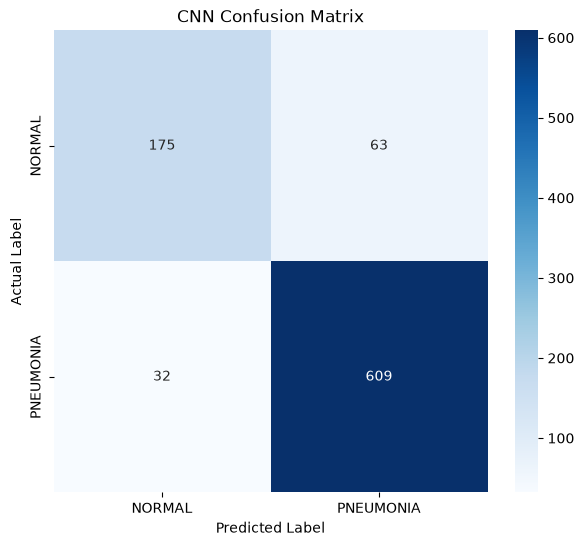

In [35]:
# Generate a confusion matrix to summarize correct and incorrect CNN predictions for each diagnostic class.

cm = confusion_matrix(
    y_test,
    cnn_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",

    xticklabels=[
        "NORMAL",
        "PNEUMONIA"
    ],

    yticklabels=[
        "NORMAL",
        "PNEUMONIA"
    ]
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)

plt.title(
    "CNN Confusion Matrix"
)

plt.show()


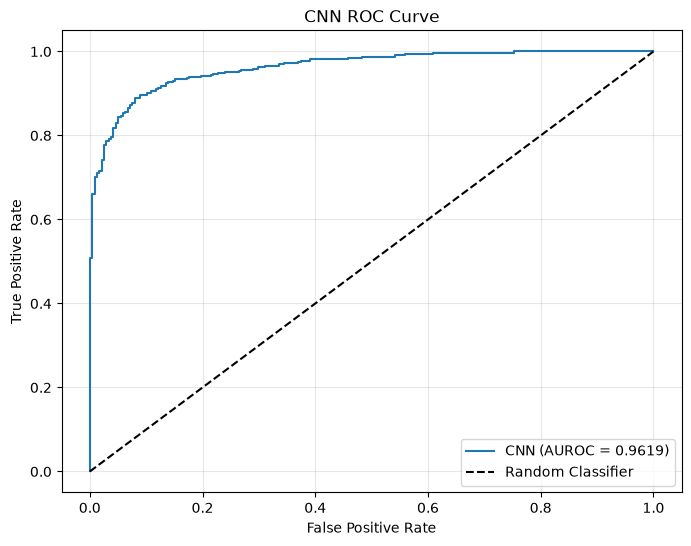

In [36]:
# Generate the Receiver Operating Characteristic (ROC) curve to visualize the trade-off between false-positive and true-positive rates.

fpr, tpr, thresholds = roc_curve(
    y_test,
    cnn_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"CNN (AUROC = {cnn_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "CNN ROC Curve"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


In [37]:
# Standardize the handcrafted HOG, LBP, and GLCM feature vectors so they can be used consistently by the classical machine-learning classifiers.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_features
)

X_val_scaled = scaler.transform(
    X_val_features
)

X_test_scaled = scaler.transform(
    X_test_features
)


In [38]:
# Train a Logistic Regression classifier using the standardized handcrafted image features and generate probability-based test predictions.

lr_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)

lr_model.fit(
    X_train_scaled,
    y_train
)

lr_probabilities = lr_model.predict_proba(
    X_test_scaled
)[:, 1]

lr_predictions = (
    lr_probabilities >= 0.5
).astype(int)


In [39]:
# Train a Random Forest classifier using the combined handcrafted image features and generate probability-based test predictions.

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(
    X_train_features,
    y_train
)

rf_probabilities = rf_model.predict_proba(
    X_test_features
)[:, 1]

rf_predictions = (
    rf_probabilities >= 0.5
).astype(int)


In [40]:
# Compute a consistent set of evaluation metrics for the CNN and classical classifiers to enable direct performance comparison.

def calculate_metrics(
    model_name,
    y_true,
    predictions,
    probabilities
):

    return {

        "Model":
            model_name,

        "Accuracy":
            accuracy_score(
                y_true,
                predictions
            ),

        "Precision":
            precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "F1-score":
            f1_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "AUROC":
            roc_auc_score(
                y_true,
                probabilities
            )
    }


results = [

    calculate_metrics(
        "CNN",
        y_test,
        cnn_predictions,
        cnn_probabilities
    ),

    calculate_metrics(
        "Logistic Regression",
        y_test,
        lr_predictions,
        lr_probabilities
    ),

    calculate_metrics(
        "Random Forest",
        y_test,
        rf_predictions,
        rf_probabilities
    )
]


results_df = pd.DataFrame(
    results
)

display(
    results_df.round(4)
)


,Model,Accuracy,Precision,Recall,F1-score,AUROC
0,CNN,0.8919,0.9062,0.9501,0.9276,0.9619
1,Logistic Regression,0.9488,0.9715,0.9579,0.9647,0.9806
2,Random Forest,0.9283,0.9544,0.9470,0.9507,0.9729


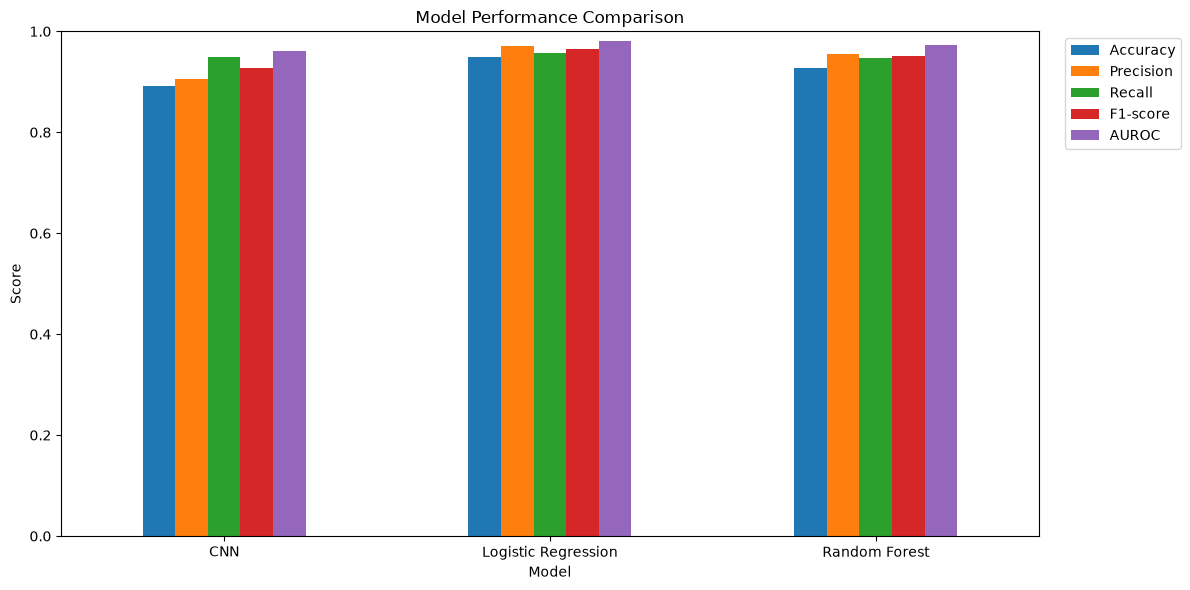

In [41]:
# Visualize the performance metrics of all evaluated models on a common scale for comparative analysis.

results_plot = results_df.set_index(
    "Model"
)

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Model Performance Comparison"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=0
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()


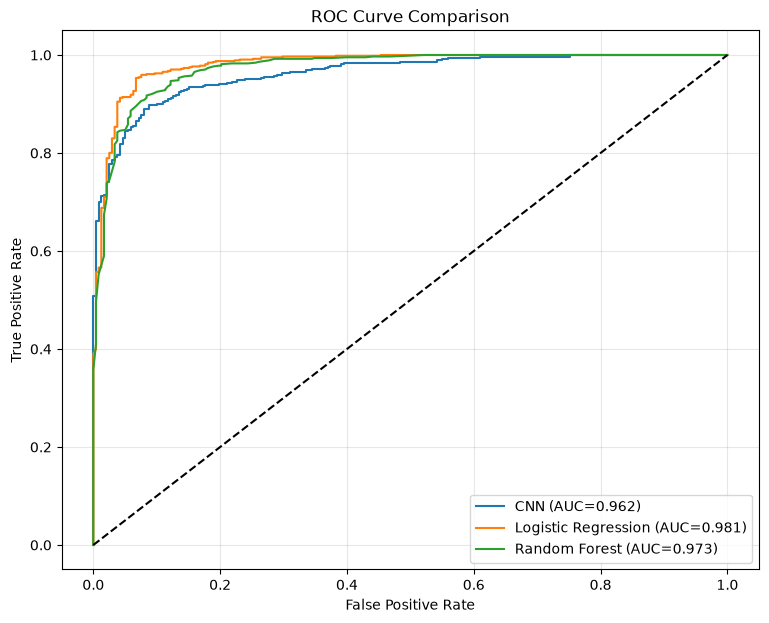

In [42]:
# Plot ROC curves for the CNN, Logistic Regression, and Random Forest models to compare their discrimination performance across classification thresholds.

plt.figure(figsize=(9, 7))

# Compute and plot the CNN ROC curve using its predicted pneumonia probabilities.
fpr_cnn, tpr_cnn, _ = roc_curve(
    y_test,
    cnn_probabilities
)

plt.plot(
    fpr_cnn,
    tpr_cnn,
    label=f"CNN (AUC={cnn_auc:.3f})"
)


# Compute and plot the Logistic Regression ROC curve using its predicted pneumonia probabilities.
fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    lr_probabilities
)

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression "
          f"(AUC={roc_auc_score(y_test, lr_probabilities):.3f})"
)


# Compute and plot the Random Forest ROC curve using its predicted pneumonia probabilities.
fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    rf_probabilities
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest "
          f"(AUC={roc_auc_score(y_test, rf_probabilities):.3f})"
)


plt.plot(
    [0, 1],
    [0, 1],
    "k--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve Comparison"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


Number of misclassified images: 95


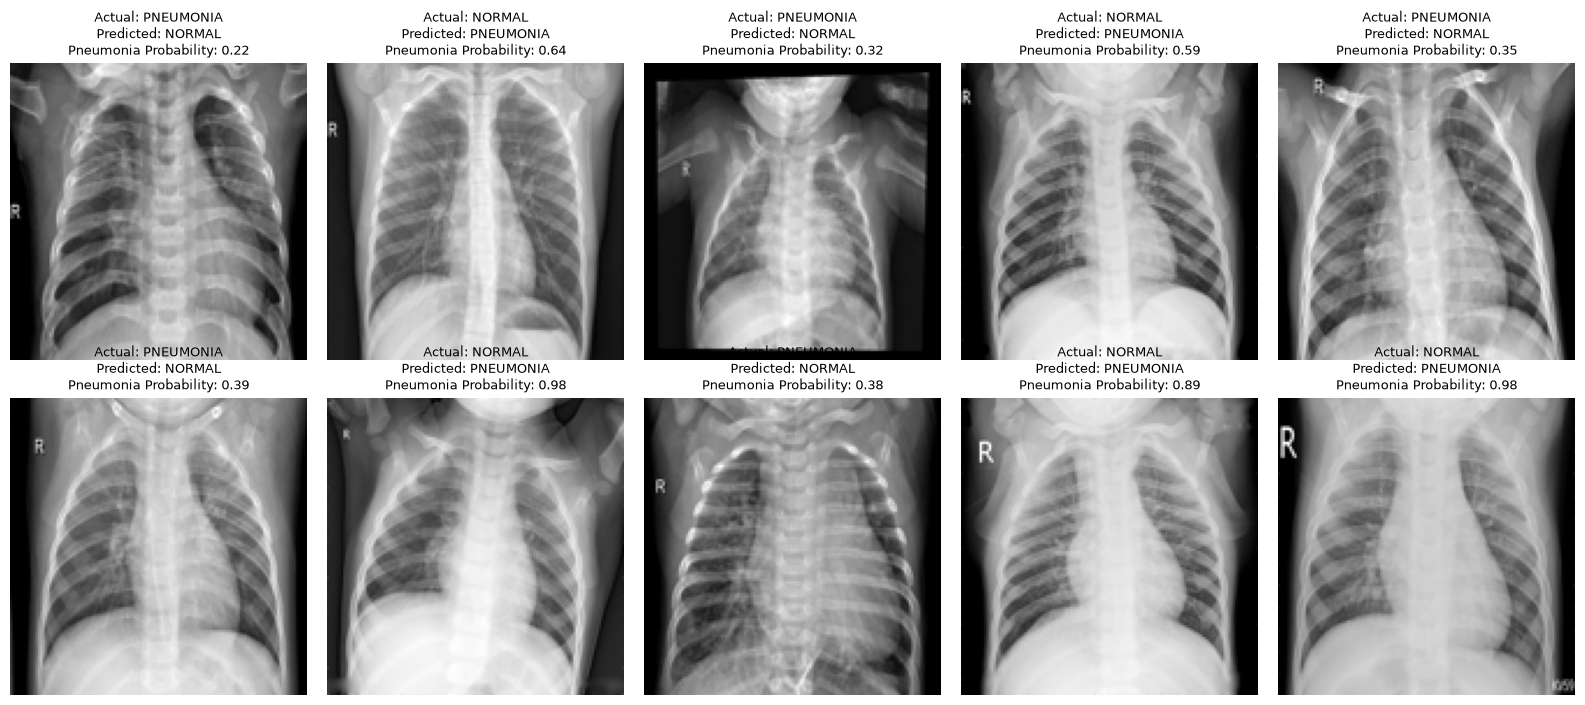

In [43]:
# Identify test images for which the CNN prediction differs from the ground-truth label and visualize selected errors for qualitative error analysis.

misclassified = np.where(
    cnn_predictions != y_test
)[0]

print(
    "Number of misclassified images:",
    len(misclassified)
)

n = min(
    10,
    len(misclassified)
)

if n > 0:

    fig, axes = plt.subplots(
        2,
        5,
        figsize=(16, 7)
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, index in zip(
        axes,
        misclassified[:n]
    ):

        ax.imshow(
            X_test[index],
            cmap="gray"
        )

        ax.set_title(
            f"Actual: "
            f"{CLASS_NAMES[y_test[index]]}\n"
            f"Predicted: "
            f"{CLASS_NAMES[cnn_predictions[index]]}\n"
            f"Pneumonia Probability: "
            f"{cnn_probabilities[index]:.2f}",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()
